# Teaching MedSAM to find an MS lesion on GluCEST, without lesion labels

**Goal.** Detect and outline the white-matter lesion of an MS patient (Subject46) on 7T GluCEST, using a model that has
only seen **healthy** brains: unsupervised anomaly detection (UAD), as in our earlier inpainting work (v7).

**Problem.** MedSAM segments what you box, but it has never seen GluCEST and has no notion of "abnormal". And there are
no lesion labels to train on.

**Approach: synthetic lesions.**
1. Take healthy GluCEST slab slices (15 healthy adults for training, 3 held out for validation; same split as v7).
2. Paint **synthetic lesions** into healthy white matter: inside a random smooth blob, shift the signal toward grey
   matter by α × (this subject's GM − WM mean), α random in 0.5–2.0. Why GM-like: the Subject46 lesion is spectrally
   GM-like (even beyond GM: Z(−3 ppm) 0.57 vs GM 0.50 vs WM 0.38).
3. Fine-tune MedSAM's **mask decoder** (the image encoder stays frozen) to outline those blobs given one box around the
   whole brain, and to output nothing on lesion-free slices.
4. Test on Subject46, which the model has never seen, against the semi-automatic lesion mask.

**Two inputs** (MedSAM takes a 3-channel image), both from SVD-denoised, B0-corrected Z-spectra:
* `glucest`: the GluCEST map only (MTRasym at 3 ppm), copied to 3 channels
* `regular`: GluCEST + Z(−3 ppm) (MT-weighted) + Z(+3 ppm)

**Caveats.** n = 1 MS patient. The lesion mask is semi-automatic, drawn on the Z(−3 ppm) image, which is also an input
channel of `regular`, so its scores are partly circular. Training: `python run.py` (see `medsam_glucest/uad.py`).

## 0. Setup and results

In [1]:
import sys, json
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import roc_curve
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.titlesize': 9})
OUT = Path('../outputs')
R = {m: np.load(OUT / f'medsam_uad_{m}.npz') for m in ['glucest', 'regular'] if (OUT / f'medsam_uad_{m}.npz').exists()}
print('results found for:', ', '.join(R))
res = pd.DataFrame([json.loads(str(r['res'])) for r in R.values()]).set_index('input')
nice = res.rename(columns={'best_val_dice': 'val Dice (synthetic, healthy held-out)', 'auc': 'Subject46 AUC',
                           'dice': 'Subject46 Dice', 'lesion_detected': 'lesion fraction detected',
                           'pred_vox': 'predicted voxels', 'false_pos_vox': 'false-positive voxels',
                           'healthy_fp_vox_per_subject': 'false-positive voxels per healthy subject',
                           'lesion_above_healthy_p99': 'lesion voxels above healthy p99'})
ref = pd.DataFrame({'Subject46 AUC': {'v7 inpainting (our previous UAD)': 0.92},
                    'lesion voxels above healthy p99': {'v7 inpainting (our previous UAD)': 0.36}})
display(pd.concat([nice, ref]).T.round(3))
# per-model display scale and threshold from the held-out healthy subjects (scores need not reach 0.5)
THR = {m: float(np.percentile(r['healthy_prob'][r['healthy_roi']], 99)) for m, r in R.items()}
VMAX = {m: max(float(np.percentile(r['prob'][r['roi']], 99.9)), 2 * THR[m], 1e-6) for m, r in R.items()}
missing = [m for m in ['glucest', 'regular'] if m not in R]
if missing: print('not finished yet:', ', '.join(missing), '- rerun this notebook when run.py is done')

results found for: glucest, regular


,glucest,regular,v7 inpainting (our previous UAD)
"val Dice (synthetic, healthy held-out)",0.000,0.465,NaN
Subject46 AUC,0.968,0.841,0.92
Subject46 Dice,0.000,0.733,NaN
lesion fraction detected,0.000,0.584,NaN
predicted voxels,0.000,942.000,NaN
false-positive voxels,0.000,15.000,NaN
false-positive voxels per healthy subject,0.000,47.667,NaN
lesion voxels above healthy p99,0.511,0.813,0.36


## 1. What the model trains on: real lesion vs synthetic lesions
Left: the real Subject46 lesion (cyan). Right: synthetic lesions painted into healthy training brains.

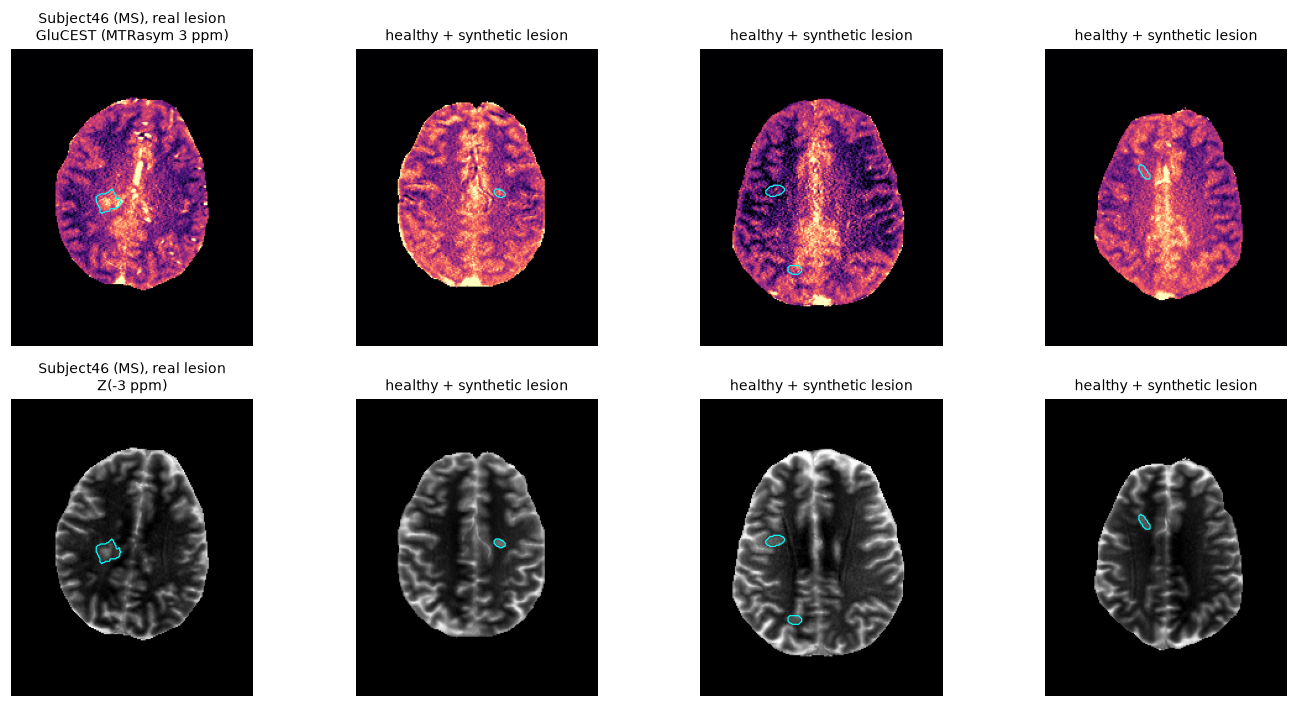

In [2]:
from medsam_glucest import uad as U
healthy = U.load_subjects('GluCEST_Scan1_B0corrected.npz')
r0 = next(iter(R.values())); win, les, roi, ch = r0['win'], r0['lesion'], r0['roi'], r0['ch']
z = int(np.argmax(les.sum((0, 1))))
x = U.to_input(ch[:, :, :, z], roi[:, :, z], win, 'combo')
sm = U.SynthSampler(healthy, U.TRAIN, win, 'combo', p_neg=0, seed=5)
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for c, nm in enumerate(['GluCEST (MTRasym 3 ppm)', 'Z(-3 ppm)']):
    ax[c, 0].imshow(x[c], cmap='magma' if c == 0 else 'gray'); ax[c, 0].contour(les[:, :, z], [0.5], colors='cyan', linewidths=0.8)
    ax[c, 0].set_title(f'Subject46 (MS), real lesion\n{nm}')
for j in range(1, 4):
    xi, t, _ = sm.sample()
    for c in range(2):
        ax[c, j].imshow(xi[c], cmap='magma' if c == 0 else 'gray'); ax[c, j].contour(t, [0.5], colors='cyan', linewidths=0.8)
        ax[c, j].set_title('healthy + synthetic lesion')
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.show()

## 2. Training
Validation every 250 steps on the 3 held-out healthy subjects: Dice on synthetic lesions, and the false-positive rate on their lesion-free slices.

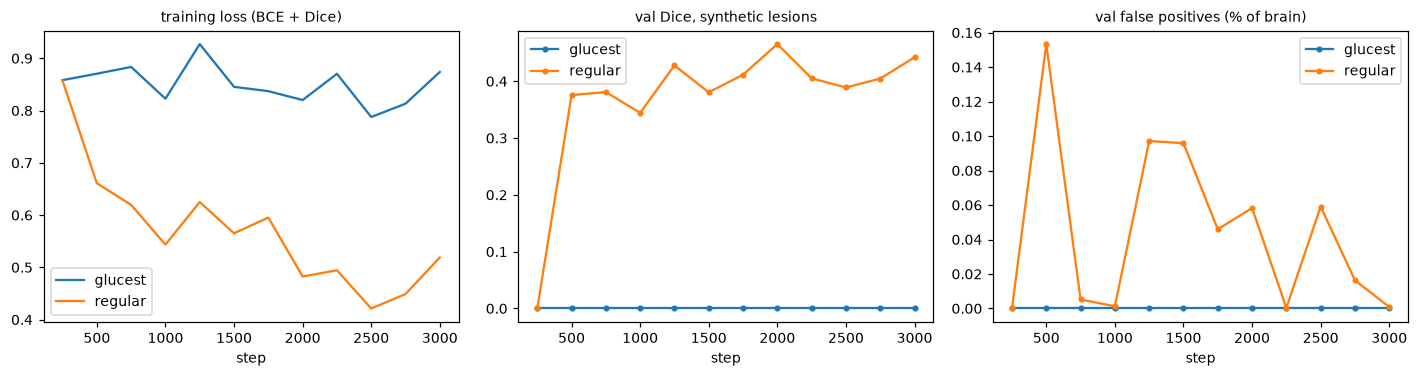

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for m, r in R.items():
    h = pd.DataFrame(json.loads(str(r['hist'])))
    ax[0].plot(h.step, h.loss, label=m); ax[1].plot(h.step, h.val_dice, marker='o', ms=3, label=m)
    ax[2].plot(h.step, 100 * h.val_fp, marker='o', ms=3, label=m)
for a, t in zip(ax, ['training loss (BCE + Dice)', 'val Dice, synthetic lesions', 'val false positives (% of brain)']):
    a.set_title(t); a.set_xlabel('step'); a.legend()
plt.tight_layout(); plt.show()

## 3. Subject46: where does the model see a lesion?
Lesion probability on every slice that contains the lesion. Cyan: semi-automatic lesion mask; green: model prediction (probability > 0.5); orange: above the 99th percentile of the held-out healthy subjects. Colour scale is per model (the `glucest` model never reaches 0.5).

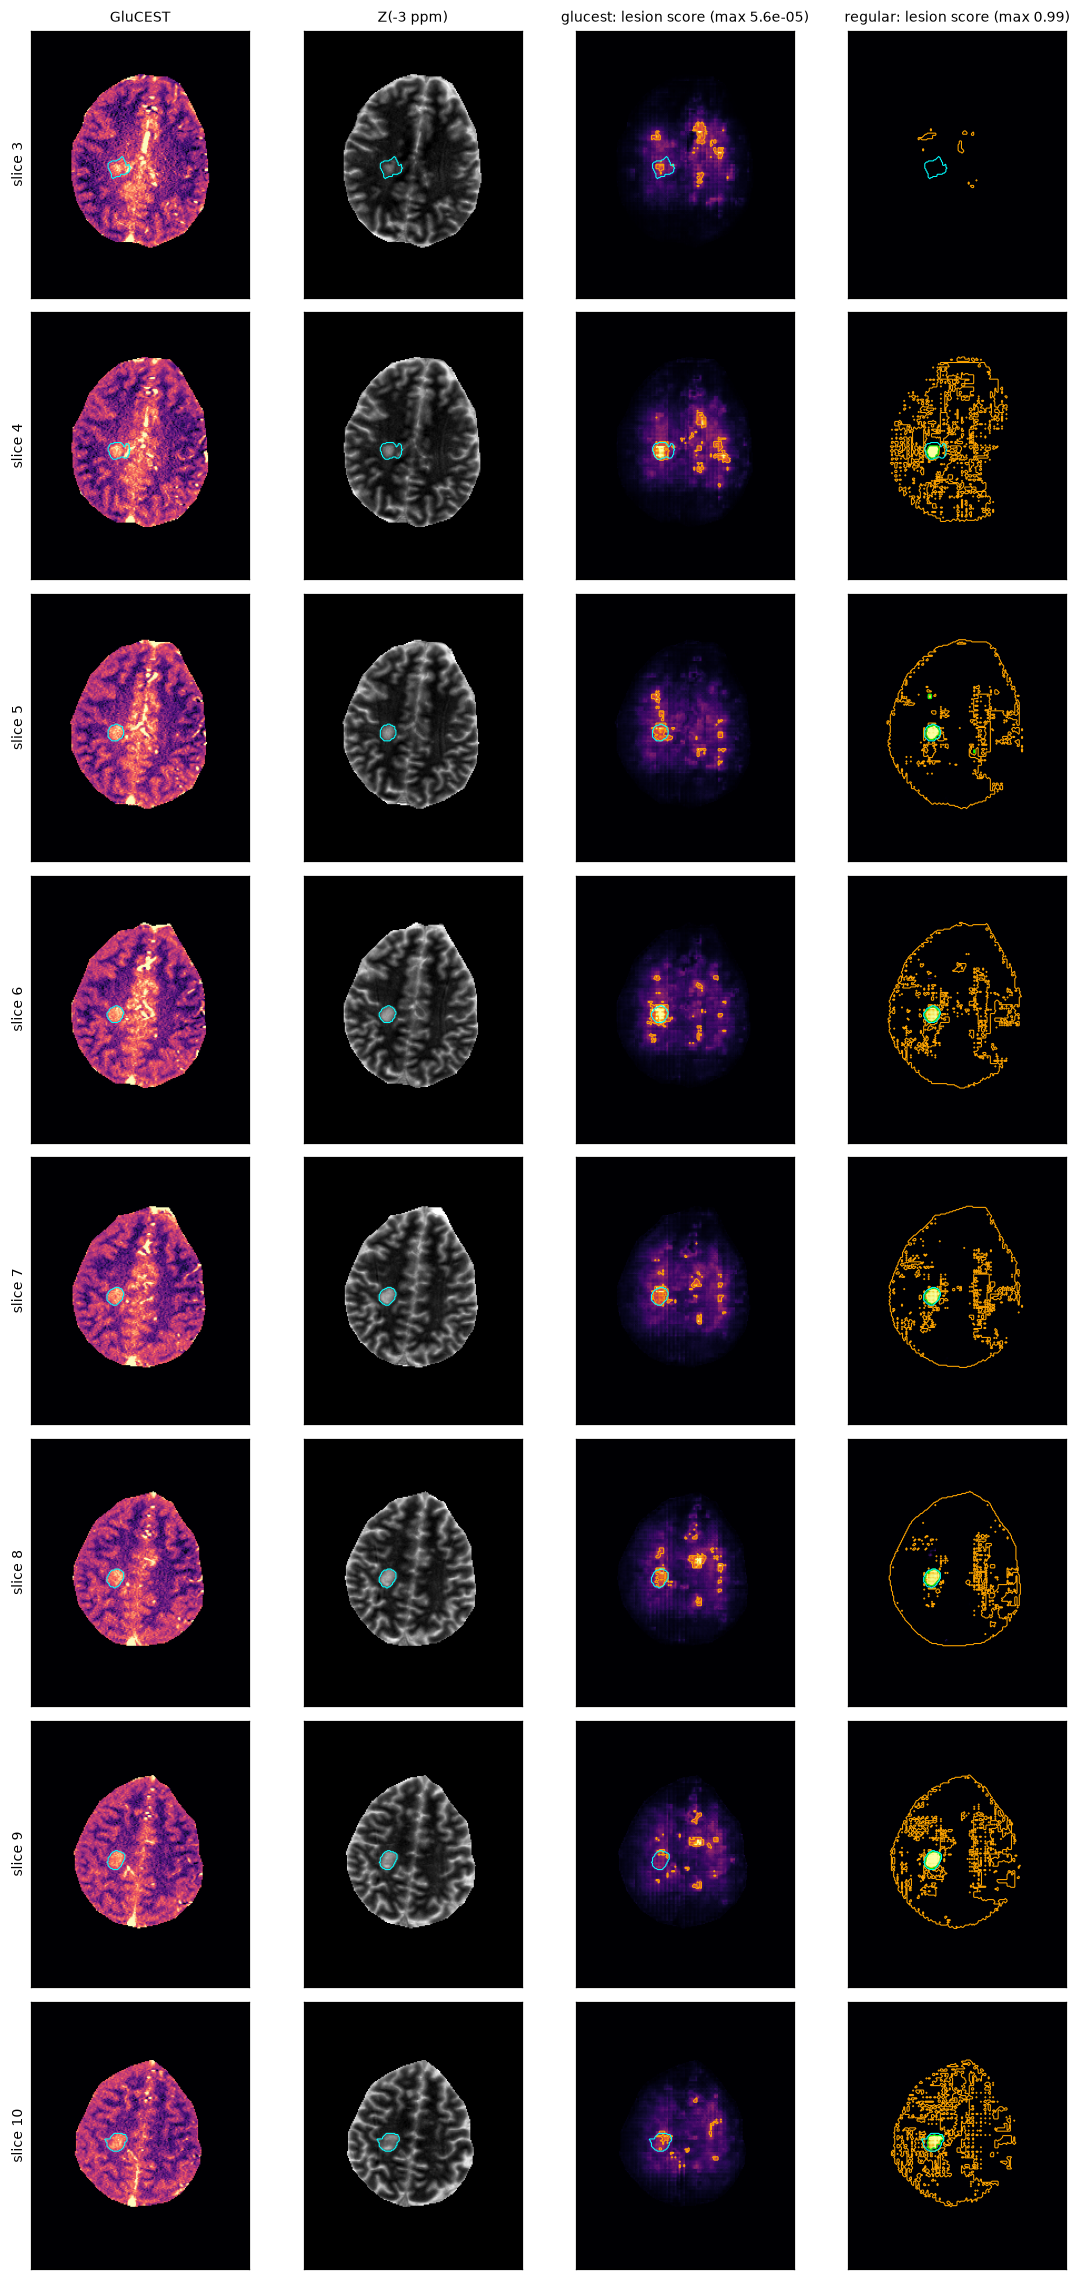

In [4]:
zs = [z for z in range(les.shape[2]) if les[:, :, z].any()]
cols = 2 + len(R)
fig, ax = plt.subplots(len(zs), cols, figsize=(2.6 * cols, 2.6 * len(zs)))
for i, z in enumerate(zs):
    x = U.to_input(ch[:, :, :, z], roi[:, :, z], win, 'combo')
    ax[i, 0].imshow(x[0], cmap='magma'); ax[i, 1].imshow(x[1], cmap='gray')
    for j, (m, r) in enumerate(R.items()):
        a = ax[i, 2 + j]; pz = r['prob'][:, :, z]; a.imshow(pz, cmap='inferno', vmin=0, vmax=VMAX[m])
        if (pz > THR[m]).any(): a.contour(pz > THR[m], [0.5], colors='orange', linewidths=0.7)
        if (pz > 0.5).any(): a.contour(pz > 0.5, [0.5], colors='lime', linewidths=0.7)
        if i == 0: a.set_title(f'{m}: lesion score (max {VMAX[m]:.2g})')
    for a in ax[i, :2]: a.contour(les[:, :, z], [0.5], colors='cyan', linewidths=0.7)
    for a in ax[i, 2:]: a.contour(les[:, :, z], [0.5], colors='cyan', linewidths=0.7)
    ax[i, 0].set_ylabel(f'slice {z}')
ax[0, 0].set_title('GluCEST'); ax[0, 1].set_title('Z(-3 ppm)')
for a in ax.flat: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 4. Healthy brains the model has never seen
False positives on the 3 held-out healthy subjects (middle slice). A useful detector should stay dark here.

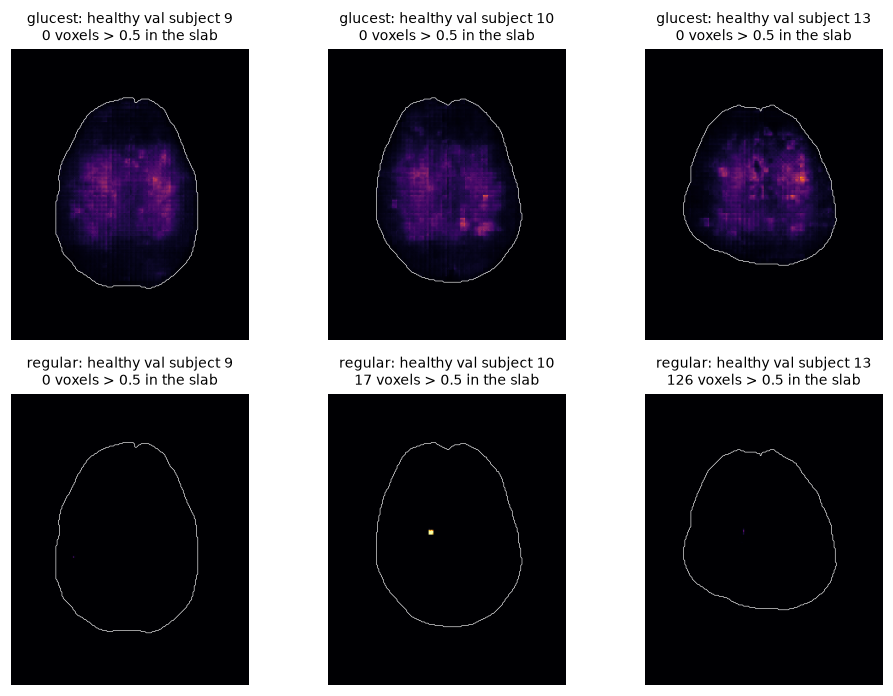

In [5]:
fig, ax = plt.subplots(len(R), 3, figsize=(9, 3.2 * len(R)), squeeze=False)
for i, (m, r) in enumerate(R.items()):
    for j in range(3):
        a = ax[i, j]; zz = 6
        a.imshow(r['healthy_prob'][j][:, :, zz], cmap='inferno', vmin=0, vmax=VMAX[m])
        a.contour(r['healthy_roi'][j][:, :, zz], [0.5], colors='white', linewidths=0.4)
        n_fp = int((r['healthy_prob'][j] > 0.5).sum())
        a.set_title(f'{m}: healthy val subject {U.VAL[j]}\n{n_fp} voxels > 0.5 in the slab'); a.axis('off')
plt.tight_layout(); plt.show()

## 5. Ranking: ROC on Subject46
AUC asks whether lesion voxels get higher scores than the rest of the brain, regardless of threshold.

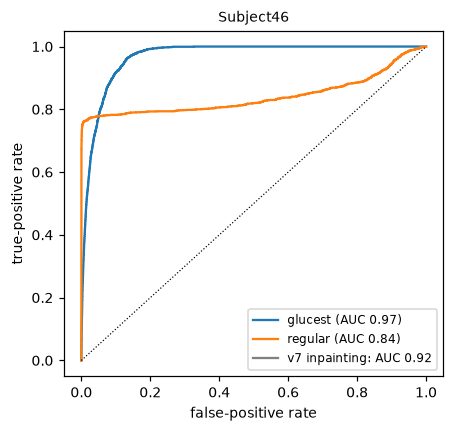

In [6]:
ev = roi.copy(); ev[:, :, [0, ev.shape[2] - 1]] = False
fig, ax = plt.subplots(figsize=(4.2, 4))
for m, r in R.items():
    fpr, tpr, _ = roc_curve(les[ev], r['prob'][ev])
    ax.plot(fpr, tpr, label=f"{m} (AUC {res.loc[m, 'auc']:.2f})")
ax.plot([0, 1], [0, 1], 'k:', lw=0.8); ax.axhline(np.nan, label='v7 inpainting: AUC 0.92', c='gray')
ax.set_xlabel('false-positive rate'); ax.set_ylabel('true-positive rate'); ax.legend(fontsize=8); ax.set_title('Subject46')
plt.tight_layout(); plt.show()

## Take-aways

| | `glucest` | `regular` | v7 inpainting |
|---|---|---|---|
| val Dice, synthetic lesions | 0.00 | 0.47 | |
| Subject46 Dice | 0.00 | **0.73** | |
| lesion fraction found | 0 % | 58 % | |
| false-positive voxels, Subject46 | 0 | 15 | |
| false-positive voxels per healthy subject | 0 | 48 | |
| Subject46 AUC | 0.97 | 0.84 | 0.92 |
| lesion voxels above healthy p99 | 51 % | 81 % | 36 % |

* **`regular` (GluCEST + Z(-3) + Z(+3)) outlines the real lesion**: Dice 0.73 on Subject46 with only 15 voxels outside
  the lesion mask, after training only on synthetic lesions in healthy brains. It finds 58 % of the lesion, and 81 % of lesion voxels score above the healthy p99 (v7: 36 %). On the 3 held-out healthy
  subjects it marks about 48 voxels per slab.
* **But it is partly circular**: the lesion mask was drawn on Z(-3 ppm), which is an input channel of `regular`.
* **`glucest` (GluCEST map only) never learned to segment** (val Dice 0 for all 3000 steps, no voxel above 0.5).
  Its faint scores still rank the lesion well (AUC 0.97, 51 % above the healthy p99), but that comes from an
  almost untrained step-250 decoder and probably tracks GM-like brightness. Not a working segmenter.
* **n = 1 MS patient**: these are proof-of-concept numbers, not a validation.
* **Encoder caveat**: these runs used `wanglab/medsam-vit-base`, whose image encoder turned out to be identical to the
  original SAM encoder (see notebook 01, section 4). So here only a decoder was trained on top of SAM features. The
  run should be repeated with the full MedSAM conversion (`flaviagiammarino/medsam-vit-base`).